# Estudo de ablação: o aumento de dados na MinhaCNN

**Introdução à Aprendizagem Profunda — APS (continuação da APS de Redes Convolucionais)**

Este notebook reúne o estudo de ablação da **MinhaCNN**, a CNN de 1,18 milhão de parâmetros da APS anterior, no MNIST e no CIFAR-10. O componente estudado é o **aumento de dados** (*data augmentation*): treinamos a mesma rede com e sem ele, mantendo todo o resto igual, e medimos o efeito com as mesmas métricas da APS anterior.

O notebook responde às três perguntas da atividade:

1. **Qual o componente escolhido para o estudo?** (seção 1)
2. **Quais os resultados com e sem este componente?** (seção 2)
3. **Qual sua opinião sobre o impacto da presença deste componente?** (seção 4)

A seção 3 traz o desafio: gráficos que mostram de onde vem a influência do componente.

O código fica nos scripts do repositório e este notebook só os chama: `src/train.py` treina um experimento, `run_ablation.py` lista e executa os 15 treinos da ablação e `src/ablation.py` faz a análise e os gráficos. O texto completo está em `relatorio/Relatorio_Ablacao_CNN.pdf`.

> Rode o notebook a partir da raiz do repositório, com o ambiente de `requirements.txt` e uma GPU com CUDA. Os treinos já estão salvos em `results/ablacao/`; por padrão o notebook só os lê.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
assert (ROOT / "src").exists(), "abra o notebook na raiz do repositório"
from src import ablation as A, style   # análise do estudo (src/ablation.py)
from run_ablation import EXPERIMENTS   # lista dos treinos da ablação

style.setup()
pd.set_option("display.max_colwidth", None)
FIG = ROOT / "figures"


def mostra(nome, largura=950):
    display(Image(filename=str(FIG / nome), width=largura))


def pct(v, d=2):
    return f"{100 * v:.{d}f}%".replace(".", ",")


def num(d, suf=""):
    return lambda v: "" if pd.isna(v) else f"{v:.{d}f}".replace(".", ",") + suf


ORDEM = {"MNIST": 0, "CIFAR-10": 1, A.COM: 0, A.SEM: 1, A.NOREG: 2}
ordena = lambda d: d.sort_values(["dataset", "configuracao", "semente"][:3 if "semente" in d else 2],
                                 key=lambda s: s.map(ORDEM) if s.name != "semente" else s)

## 0. Como os modelos foram treinados

Cada linha abaixo é um treino independente, rodado por `run_ablation.py`. As configurações principais têm 3 sementes (42, 43 e 44). A semente 42 **com** aumento de dados não aparece na lista porque é o próprio modelo da APS anterior (`results/minhacnn_mnist` e `results/minhacnn_cifar10`), treinado com o mesmo código e os mesmos hiperparâmetros.

- `--no-aug` desliga só o aumento de dados. Dropout, weight decay e label smoothing continuam ligados.
- `--crop-pad N` muda o deslocamento máximo do recorte aleatório no CIFAR-10 (0 desliga o recorte).
- `--no-flip` tira o espelhamento horizontal.

Para treinar tudo de novo, mude `RETREINAR` para `True` na célula seguinte.

In [2]:
cmds = pd.DataFrame({
    "experimento": list(EXPERIMENTS),
    "comando": [f"python -m src.train --subdir ablacao --tag {t} {a}" for t, a in EXPERIMENTS.items()],
})
cmds

,experimento,comando
0,mnist_sem_s42,python -m src.train --subdir ablacao --tag mnist_sem_s42 --dataset mnist --model minhacnn --epochs 15 --lr 0.1 --wd 5e-4 --no-aug --seed 42
1,cifar10_sem_s42,python -m src.train --subdir ablacao --tag cifar10_sem_s42 --dataset cifar10 --model minhacnn --epochs 40 --lr 0.1 --wd 5e-4 --no-aug --seed 42
2,mnist_sem_s43,python -m src.train --subdir ablacao --tag mnist_sem_s43 --dataset mnist --model minhacnn --epochs 15 --lr 0.1 --wd 5e-4 --no-aug --seed 43
3,cifar10_sem_s43,python -m src.train --subdir ablacao --tag cifar10_sem_s43 --dataset cifar10 --model minhacnn --epochs 40 --lr 0.1 --wd 5e-4 --no-aug --seed 43
4,mnist_com_s43,python -m src.train --subdir ablacao --tag mnist_com_s43 --dataset mnist --model minhacnn --epochs 15 --lr 0.1 --wd 5e-4 --seed 43
5,cifar10_com_s43,python -m src.train --subdir ablacao --tag cifar10_com_s43 --dataset cifar10 --model minhacnn --epochs 40 --lr 0.1 --wd 5e-4 --seed 43
6,mnist_sem_s44,python -m src.train --subdir ablacao --tag mnist_sem_s44 --dataset mnist --model minhacnn --epochs 15 --lr 0.1 --wd 5e-4 --no-aug --seed 44
7,cifar10_sem_s44,python -m src.train --subdir ablacao --tag cifar10_sem_s44 --dataset cifar10 --model minhacnn --epochs 40 --lr 0.1 --wd 5e-4 --no-aug --seed 44
8,mnist_com_s44,python -m src.train --subdir ablacao --tag mnist_com_s44 --dataset mnist --model minhacnn --epochs 15 --lr 0.1 --wd 5e-4 --seed 44
9,cifar10_com_s44,python -m src.train --subdir ablacao --tag cifar10_com_s44 --dataset cifar10 --model minhacnn --epochs 40 --lr 0.1 --wd 5e-4 --seed 44


In [3]:
RETREINAR = False  # True: treina de novo os 15 experimentos (~80 min numa RTX 3050 Laptop)
if RETREINAR:
    import subprocess
    subprocess.run([sys.executable, "run_ablation.py", "--train-only", "--force"], check=True)

## 1. Qual o componente escolhido?

O **aumento de dados**. A cada época, cada imagem de treino passa por uma transformação aleatória antes de entrar na rede; validação e teste usam sempre a imagem original.

- **CIFAR-10:** recorte aleatório com 4 px de borda refletida (o objeto se desloca até 4 px) e espelhamento horizontal com probabilidade 0,5.
- **MNIST:** rotação de até ±10°, translação de até ±8% (±2,2 px) e escala de 0,9 a 1,1, sem espelhamento.

**Por que este componente:**

1. Na APS anterior, desligar quatro regularizadores ao mesmo tempo (aumento de dados, dropout, weight decay e label smoothing) custou 6,3 p.p. no CIFAR-10, mas não dava para saber quanto vinha de cada um.
2. É o único regularizador que mexe nos dados e não no modelo: ele ensina à rede que um objeto deslocado ou espelhado continua sendo o mesmo objeto.
3. A ablação é limpa: ligar e desligar o aumento não muda a arquitetura, o número de parâmetros nem o custo de inferência.

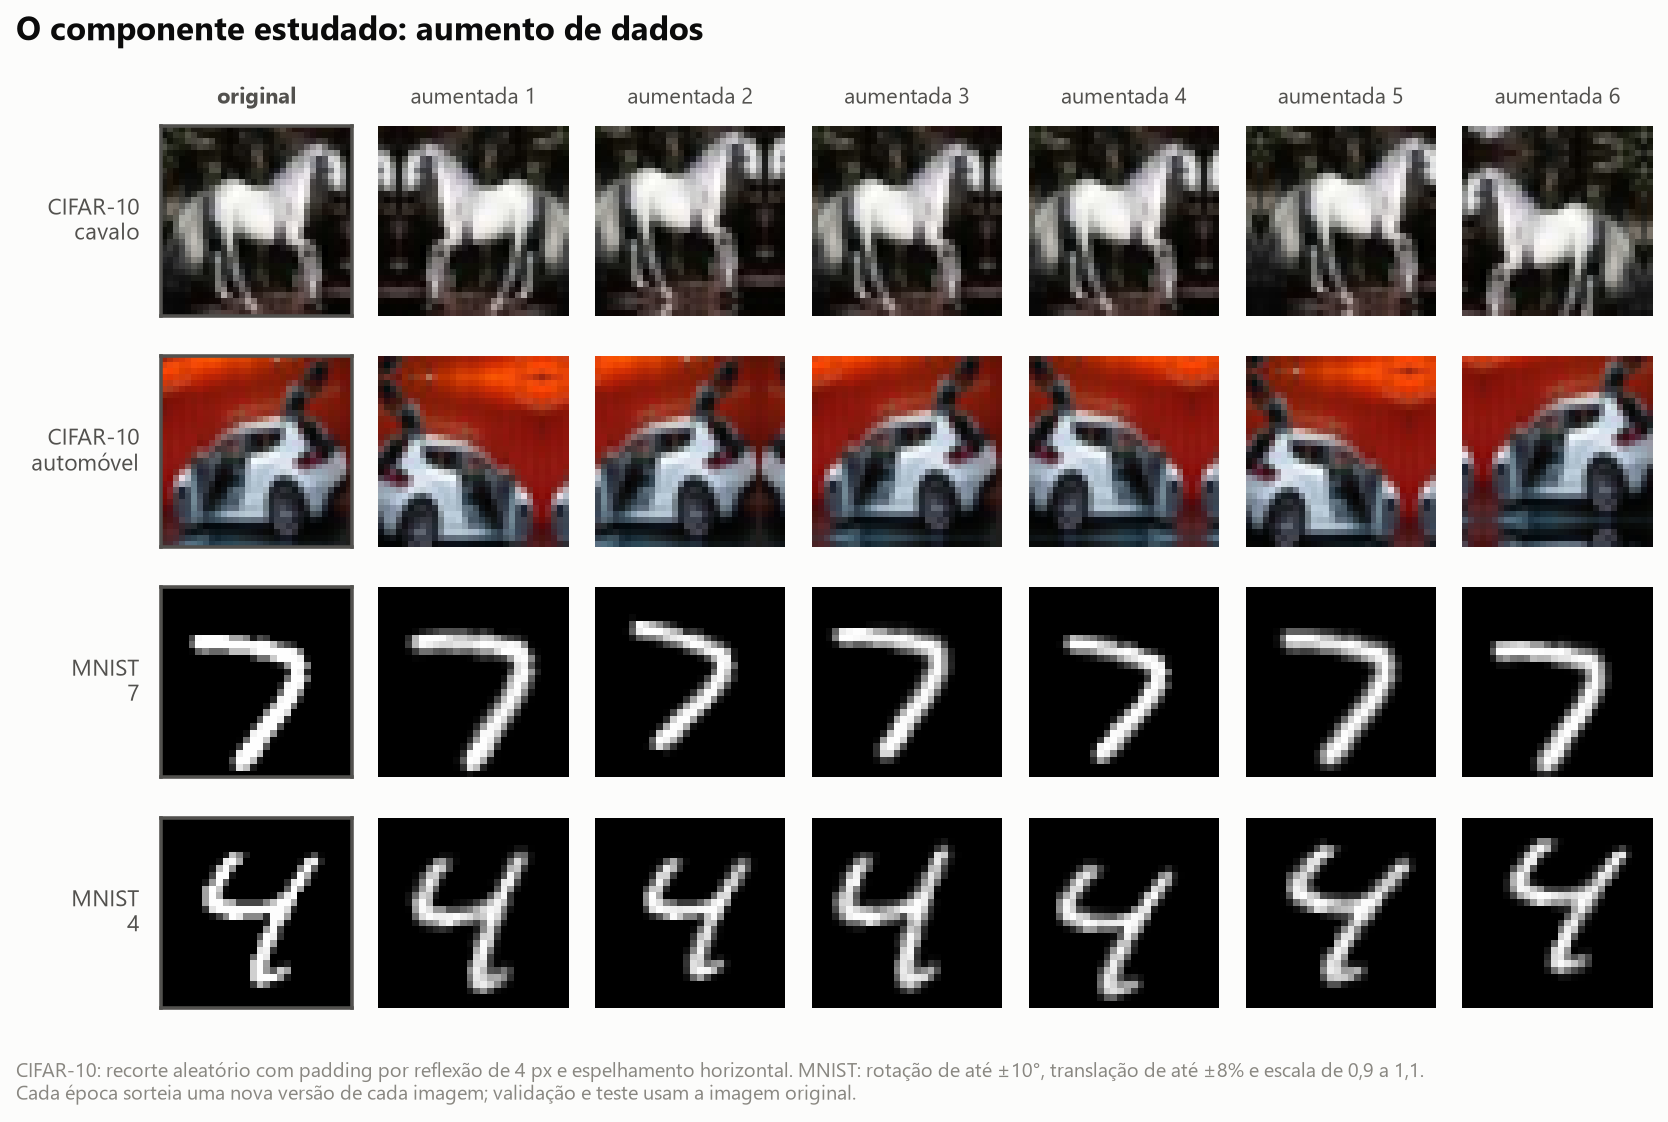

In [4]:
A.fig_examples()
mostra("ablacao_exemplos.png")

## 2. Quais os resultados com e sem o componente?

Mesmo protocolo da APS anterior: o checkpoint de cada treino é a época de maior acurácia na validação (5.000 imagens) e o teste oficial (10.000 imagens) é avaliado uma vez. *Acc. treino* é medida no treino sem aumento de dados e sem dropout; *gap* é a diferença entre ela e a acurácia de teste.

In [5]:
runs = A.load_all()
A.summary(runs)                 # results/ablacao/resumo_ablacao.csv e .md
est = A.statistics(runs)        # results/ablacao/estatistica_ablacao.json
print(len(runs), "execuções carregadas")

df = pd.read_csv(ROOT / "results" / "ablacao" / "resumo_ablacao.csv")
principais = ordena(df[df.configuracao.isin([A.COM, A.SEM, A.NOREG])].copy())
principais["gap (p.p.)"] = 100 * principais.gap_treino_teste
tab = principais[["dataset", "configuracao", "semente", "acc_teste", "erros", "f1_macro",
                  "acc_treino_limpo", "gap (p.p.)", "perda_teste", "melhor_epoca"]]
tab.style.format({"acc_teste": pct, "acc_treino_limpo": pct, "f1_macro": num(4),
                  "gap (p.p.)": num(2), "perda_teste": num(3)}).hide(axis="index")

18 execuções carregadas


dataset,configuracao,semente,acc_teste,erros,f1_macro,acc_treino_limpo,gap (p.p.),perda_teste,melhor_epoca
MNIST,Com aumento de dados,42,"99,66%",34,"0,9966","99,82%","0,16","0,097",13
MNIST,Com aumento de dados,43,"99,70%",30,"0,9970","99,82%","0,12","0,097",13
MNIST,Com aumento de dados,44,"99,69%",31,"0,9969","99,87%","0,18","0,097",14
MNIST,Sem aumento de dados,42,"99,70%",30,"0,9970","99,96%","0,26","0,098",13
MNIST,Sem aumento de dados,43,"99,72%",28,"0,9972","99,98%","0,26","0,098",15
MNIST,Sem aumento de dados,44,"99,69%",31,"0,9969","99,96%","0,27","0,095",13
CIFAR-10,Com aumento de dados,42,"92,43%",757,"0,9240","98,16%","5,73","0,303",39
CIFAR-10,Com aumento de dados,43,"92,13%",787,"0,9210","98,23%","6,10","0,303",40
CIFAR-10,Com aumento de dados,44,"92,11%",789,"0,9207","98,18%","6,07","0,304",40
CIFAR-10,Sem aumento de dados,42,"90,06%",994,"0,9001","100,00%","9,94","0,390",37


In [6]:
media = (principais.groupby(["dataset", "configuracao"], sort=False)
         .agg(sementes=("semente", "count"), acc_media=("acc_teste", "mean"),
              acc_dp=("acc_teste", "std"), erros=("erros", "mean"), f1=("f1_macro", "mean"),
              gap_pp=("gap (p.p.)", "mean"), perda=("perda_teste", "mean"))
         .reset_index())
media["acc_dp"] *= 100
ordena(media).style.format({"acc_media": pct, "acc_dp": num(2, " p.p."), "erros": num(0), "f1": num(4),
                            "gap_pp": num(2), "perda": num(3)}).hide(axis="index")

dataset,configuracao,sementes,acc_media,acc_dp,erros,f1,gap_pp,perda
MNIST,Com aumento de dados,3,"99,68%","0,02 p.p.",32,"0,9968","0,15","0,097"
MNIST,Sem aumento de dados,3,"99,70%","0,02 p.p.",30,"0,9970","0,26","0,097"
CIFAR-10,Com aumento de dados,3,"92,22%","0,18 p.p.",778,"0,9219","5,96","0,303"
CIFAR-10,Sem aumento de dados,3,"89,97%","0,20 p.p.",1003,"0,8992","10,03","0,389"
CIFAR-10,Sem nenhuma regularização,1,"86,17%",,1383,"0,8616","13,83","0,765"


In [7]:
linhas = []
for ds in ("mnist", "cifar10"):
    e = est[ds]
    for m in e["mcnemar"]:
        linhas.append({"dataset": A.DS_NAME[ds], "semente": m["semente"],
                       "só com aumento acerta": m["so_com_acerta"],
                       "só sem aumento acerta": m["so_sem_acerta"], "p (McNemar)": m["p_valor"]})
    print(f"{A.DS_NAME[ds]}: com {pct(e['media_com'])} x sem {pct(e['media_sem'])} -> "
          f"diferença {e['diferenca_pp']:+.2f} p.p.; erros {e['erros_sem']:.0f} -> {e['erros_com']:.0f} "
          f"({e['reducao_erros_pct']:+.1f}% de redução); Welch p = {e['welch_p']:.2g}")
esc = est["cifar10_escada_s42"]
print(f"CIFAR-10, semente 42: {pct(esc['com'])} -> sem aumento {pct(esc['sem_aumento'])} -> "
      f"sem regularização {pct(esc['sem_regularizacao'])}; o aumento explica "
      f"{100 * esc['fracao_explicada_pelo_aumento']:.0f}% da queda")
pd.DataFrame(linhas).style.format({"p (McNemar)": lambda v: f"{v:.2g}".replace(".", ",")}).hide(axis="index")

MNIST: com 99,68% x sem 99,70% -> diferença -0.02 p.p.; erros 30 -> 32 (-6.7% de redução); Welch p = 0.26
CIFAR-10: com 92,22% x sem 89,97% -> diferença +2.26 p.p.; erros 1003 -> 778 (+22.5% de redução); Welch p = 0.00013
CIFAR-10, semente 42: 92,43% -> sem aumento 90,06% -> sem regularização 86,17%; o aumento explica 38% da queda


dataset,semente,só com aumento acerta,só sem aumento acerta,p (McNemar)
MNIST,42,13,17,"0,58"
MNIST,43,11,13,"0,84"
MNIST,44,12,12,1
CIFAR-10,42,485,248,"1,4e-18"
CIFAR-10,43,486,247,"7,3e-19"
CIFAR-10,44,451,250,"2,8e-14"


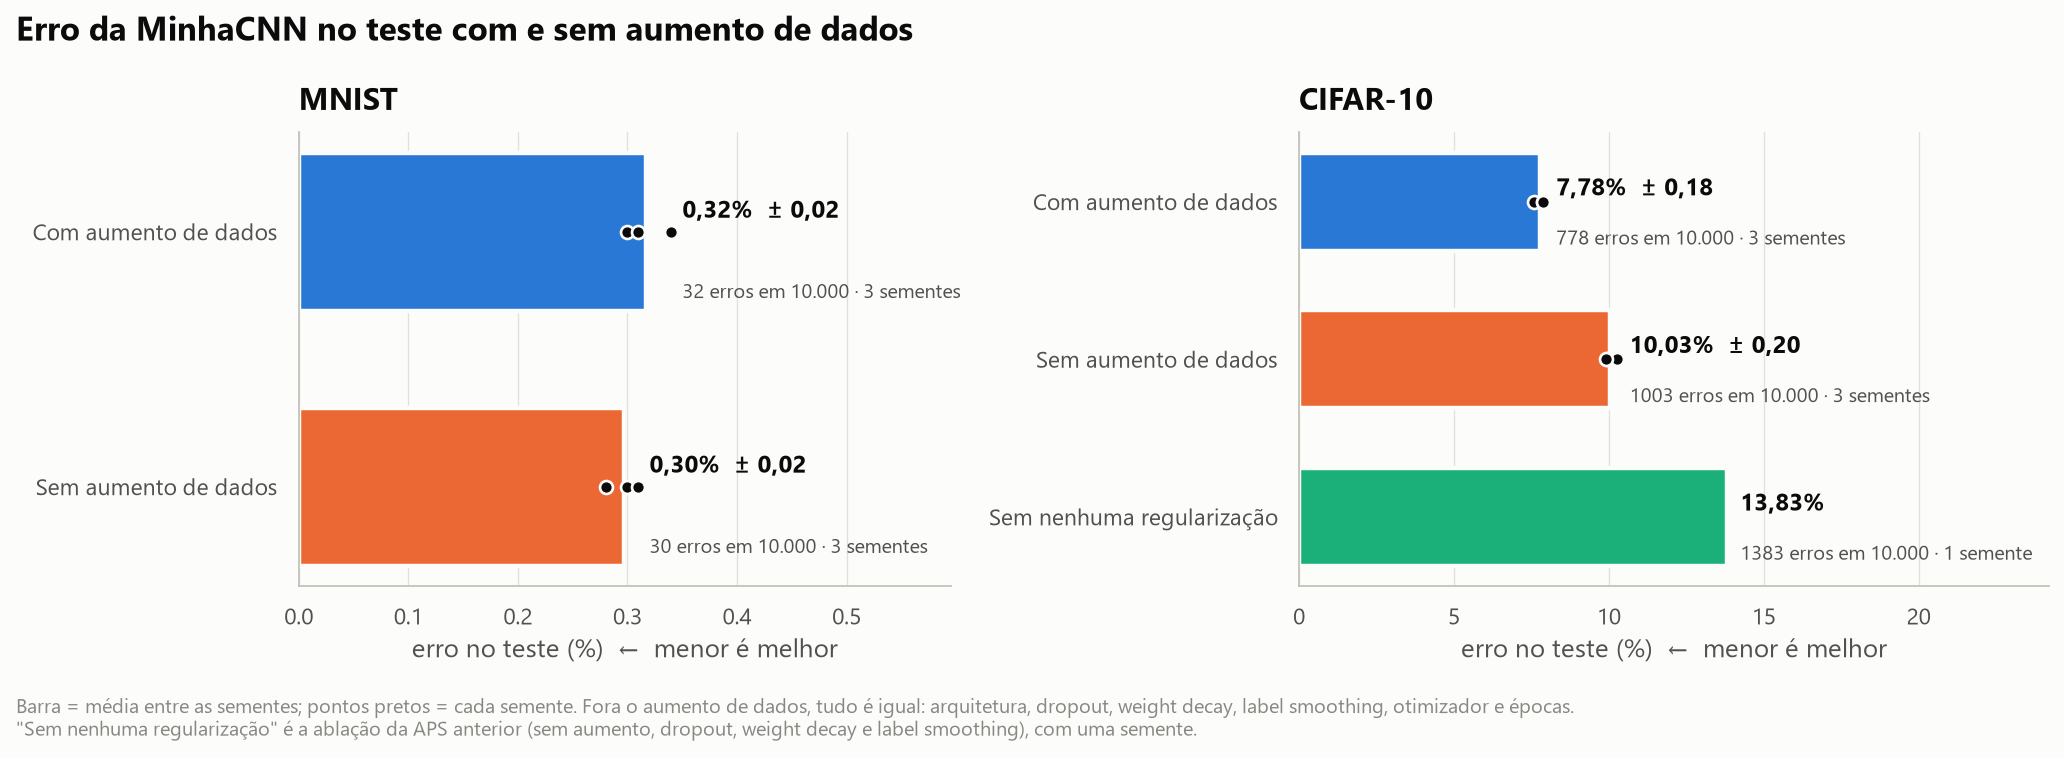

In [8]:
A.fig_result(runs)
mostra("ablacao_resultado.png")

**Leitura dos resultados:**

- **CIFAR-10 — o componente faz muita diferença.** Sem aumento de dados a acurácia cai de **92,22%** para **89,97%** (−2,26 p.p.) e os erros sobem de 778 para 1.003 em 10.000 imagens: 22% menos erros com o componente. A queda é dez vezes maior que a variação entre sementes (0,2 p.p.), as três sementes "sem" ficaram abaixo das três "com" e o McNemar dá p < 10⁻¹³ em cada semente: em cada uma, as imagens que só o modelo com aumento acerta são quase o dobro das que só o modelo sem ele acerta.
- **MNIST — empate.** 99,68% com e 99,70% sem: 2 imagens de diferença em 10.000, dentro do intervalo de confiança (±0,11 p.p.) e com p ≥ 0,58 em todas as sementes. O componente não melhora nem piora a acurácia de teste no MNIST.
- **Quanto da regularização é aumento de dados.** Na semente 42 do CIFAR-10: 92,43% com tudo → 90,06% sem aumento de dados → 86,17% sem nenhuma regularização. O aumento de dados explica **38%** da queda de 6,3 p.p. que a APS anterior atribuía à regularização; os outros 62% vêm de dropout, weight decay e label smoothing juntos.

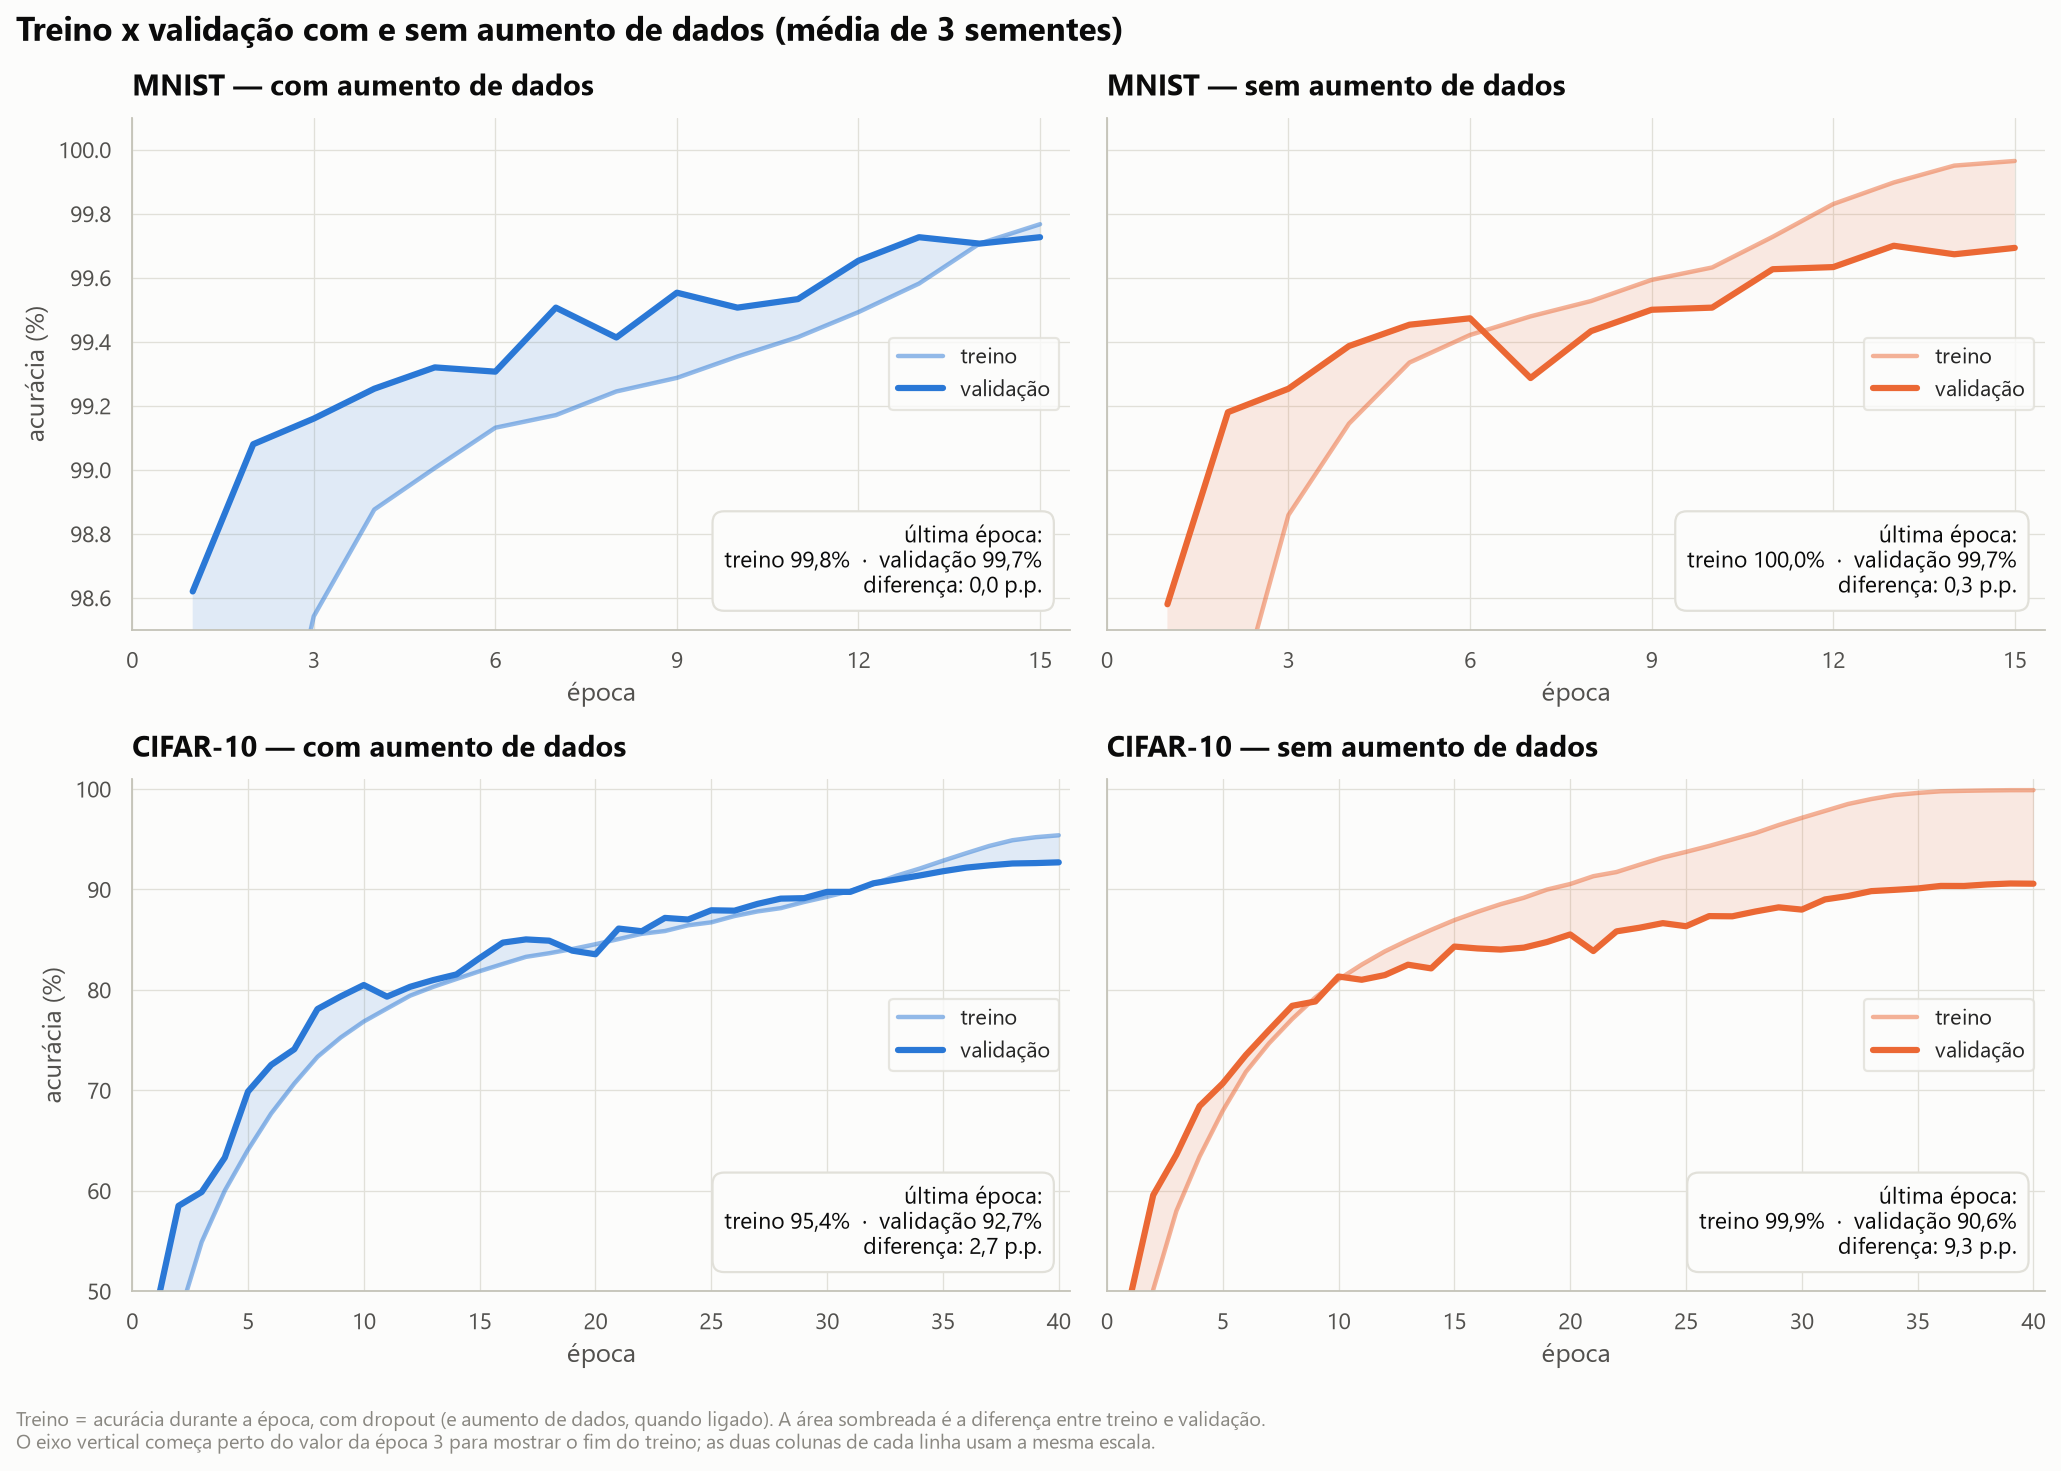

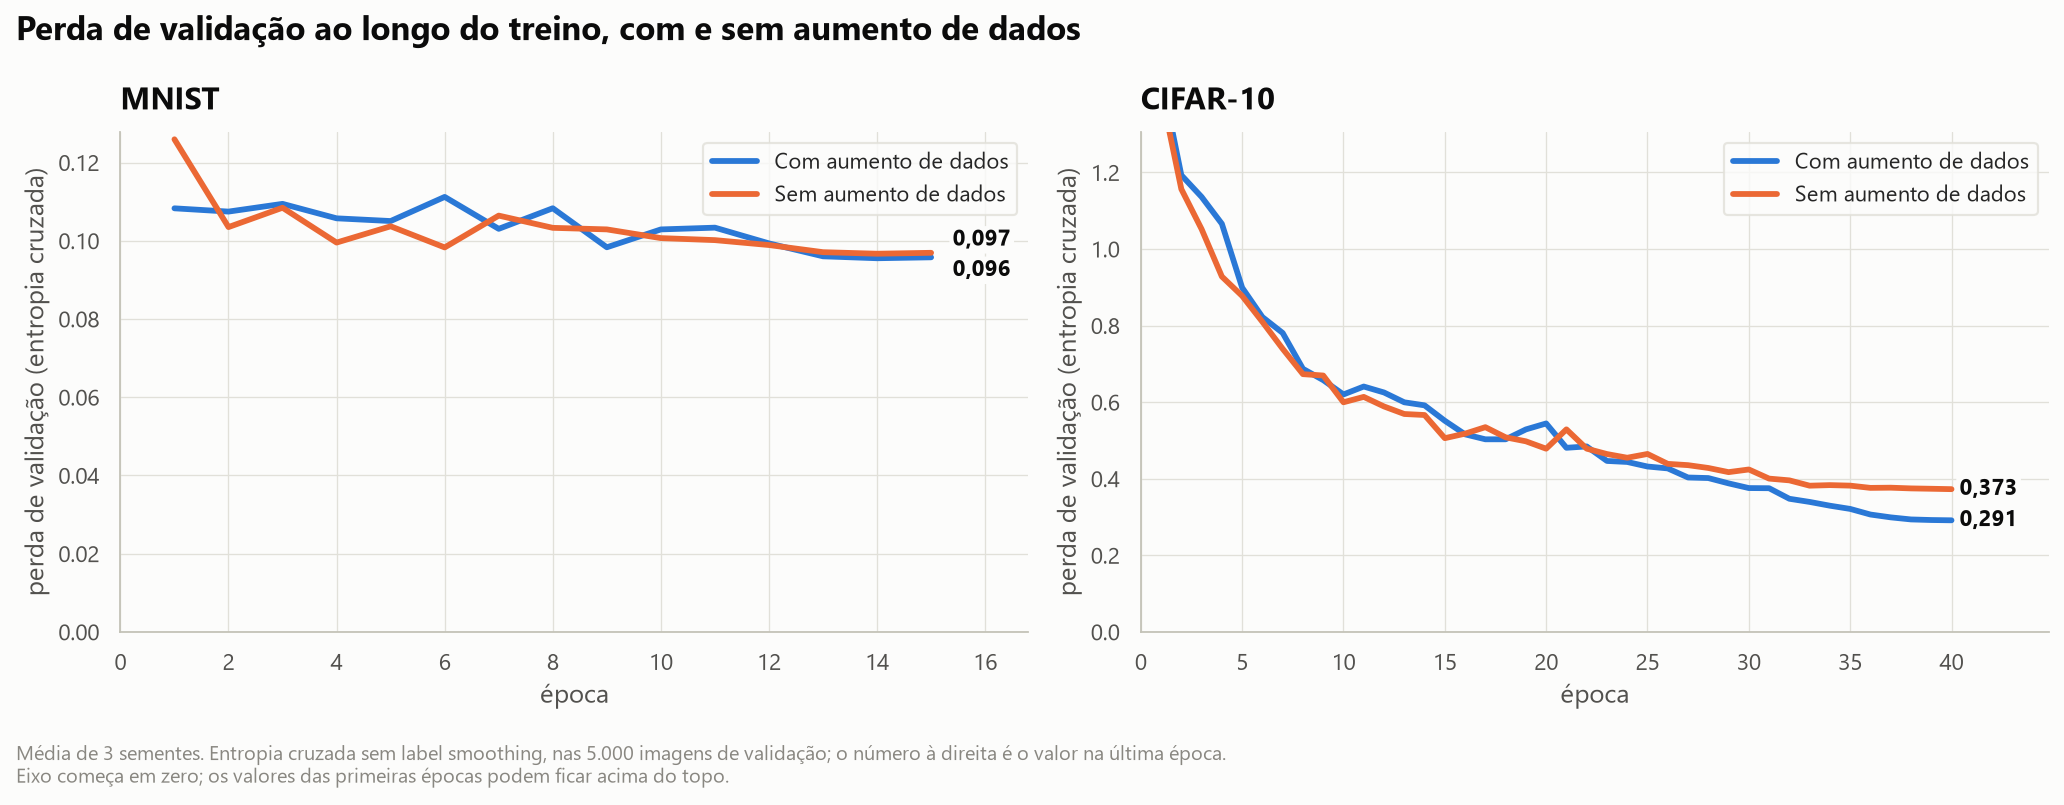

In [9]:
A.fig_curves(runs)
mostra("ablacao_curvas.png")
A.fig_val_loss(runs)
mostra("ablacao_perda_validacao.png")

Sem aumento de dados a MinhaCNN **decora o CIFAR-10**: a acurácia de treino passa de 99% por volta da época 33 e termina em 100,00% nas três sementes, enquanto o teste fica em 90%. O gap treino − teste sobe de 6,0 para 10,0 p.p. Com o componente a rede termina com 98,2% no treino, e a melhor época de validação é a última: ela ainda estava aprendendo quando o treino acabou.

A perda de validação mostra o mesmo: as curvas andam juntas por cerca de 25 épocas e depois se separam (0,291 contra 0,373 no fim). Ela não chega a subir, como no modelo sem nenhuma regularização da APS anterior, porque dropout, weight decay e label smoothing continuam ligados.

No MNIST o gap passa de 0,15 para 0,26 p.p. e a validação fica igual: o problema é simples e as outras técnicas já seguram o sobreajuste.

## 3. Desafio: de onde vem a influência do componente

Três perguntas, cada uma com um gráfico:

1. Qual parte do aumento de dados rende mais, e quanto aumentar? (só espelhamento, só recorte e recortes de ±0 a ±8 px no CIFAR-10)
2. O que a rede aprende com o componente? (acurácia no teste deslocado, espelhado, girado, ampliado ou com ruído)
3. Onde o ganho aparece? (acurácia por classe no CIFAR-10)

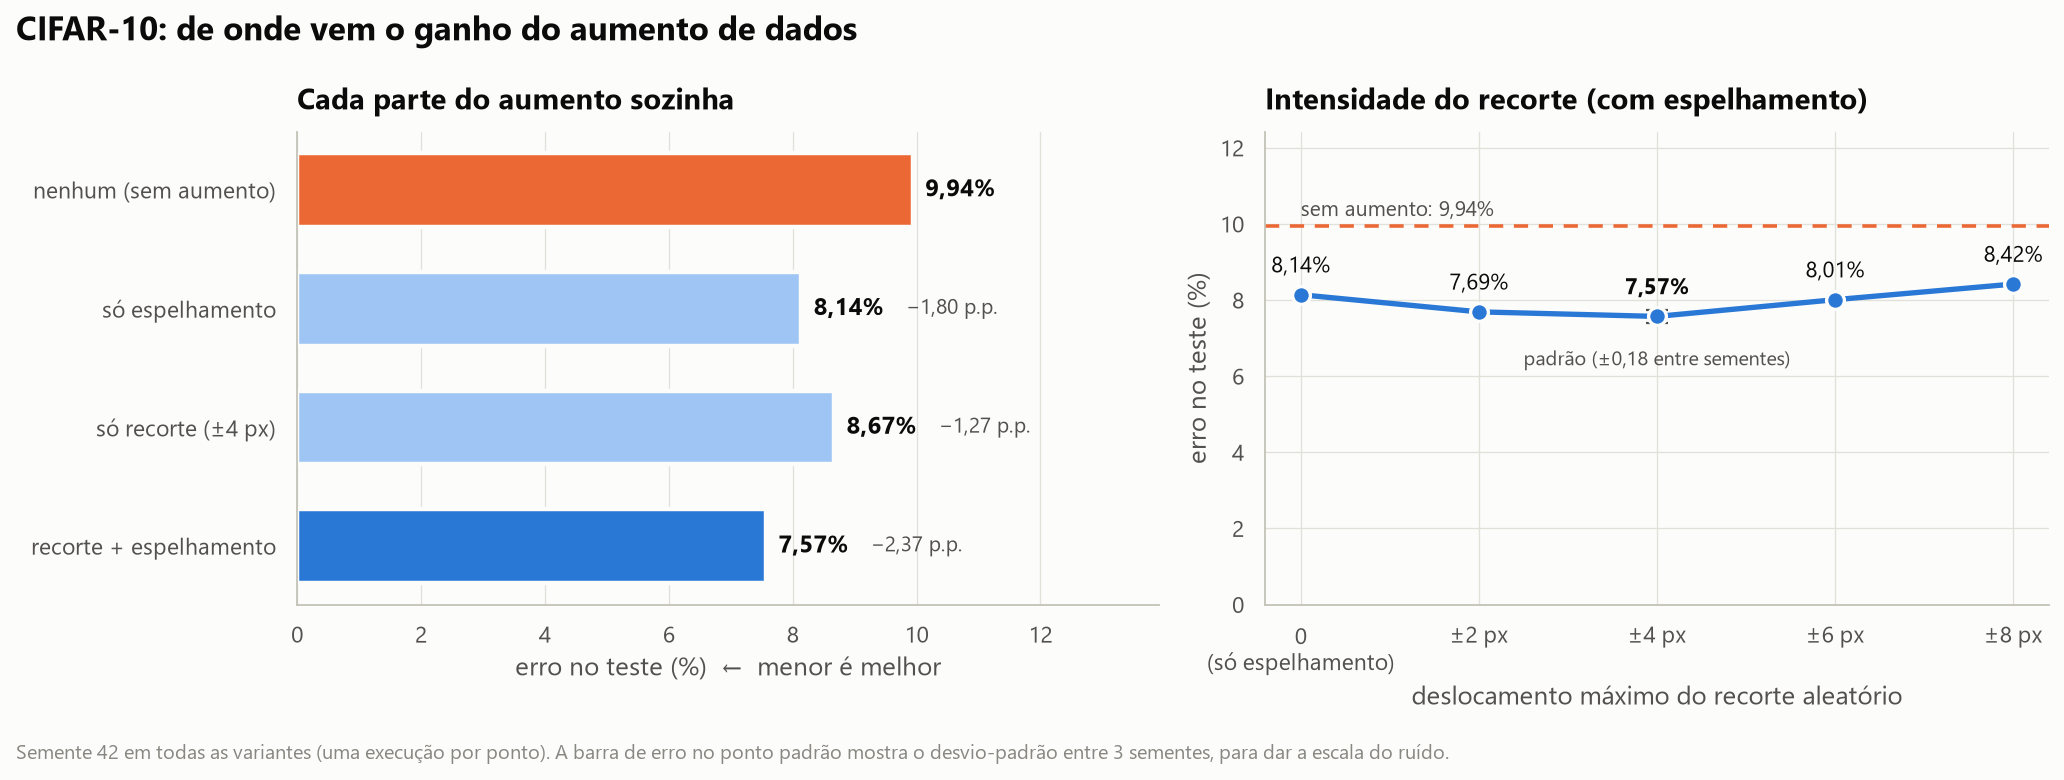

configuracao,acc_teste,erros,acc_treino_limpo,perda_teste
Sem aumento de dados,"90,06%",994,"100,00%","0,390"
Só espelhamento,"91,86%",814,"99,88%","0,322"
Só recorte (±4 px),"91,33%",867,"99,79%","0,335"
Recorte ±2 px + espelhamento,"92,31%",769,"98,68%","0,302"
Com aumento de dados,"92,43%",757,"98,16%","0,303"
Recorte ±6 px + espelhamento,"91,99%",801,"97,40%","0,309"
Recorte ±8 px + espelhamento,"91,58%",842,"96,87%","0,327"
Sem nenhuma regularização,"86,17%",1383,"100,00%","0,765"


In [10]:
A.fig_parts(runs)
mostra("ablacao_partes_cifar10.png")
var = df[(df.dataset == "CIFAR-10") & (df.semente == 42)][["configuracao", "acc_teste", "erros", "acc_treino_limpo", "perda_teste"]]
ordem_var = [A.CFG_NAME[c] for c in ("sem", "flip", "crop", "pad2", "com", "pad6", "pad8", "noreg")]
var = var.set_index("configuracao").loc[[c for c in ordem_var if c in set(var.configuracao)]].reset_index()
var.style.format({"acc_teste": pct, "acc_treino_limpo": pct, "perda_teste": num(3)}).hide(axis="index")

- **As duas partes ajudam, e o espelhamento ajuda mais:** +1,80 p.p. sozinho, contra +1,27 p.p. do recorte. No CIFAR-10 um objeto virado para a esquerda é tão comum quanto um virado para a direita.
- **As partes se sobrepõem:** juntas rendem +2,37 p.p., menos que a soma (+3,07 p.p.). Com uma parte só a rede ainda decora 99,8–99,9% do treino; com as duas, 98,2%.
- **Mais intensidade não é sempre melhor:** o erro é menor entre ±2 e ±4 px e volta a subir com ±6 e ±8 px. O gap cai sempre (8,0 → 5,3 p.p.), mas a acurácia de treino também (99,9% → 96,9%): com 8 px de deslocamento numa imagem de 32 px parte do objeto sai do quadro, e em 40 épocas a rede passa a ter dificuldade até para aprender o treino (*underfitting*).

_Uma execução por variante (semente 42). O desvio-padrão entre sementes da configuração padrão é 0,18 p.p.: diferenças menores que ~0,4 p.p. entre variantes não são confiáveis._

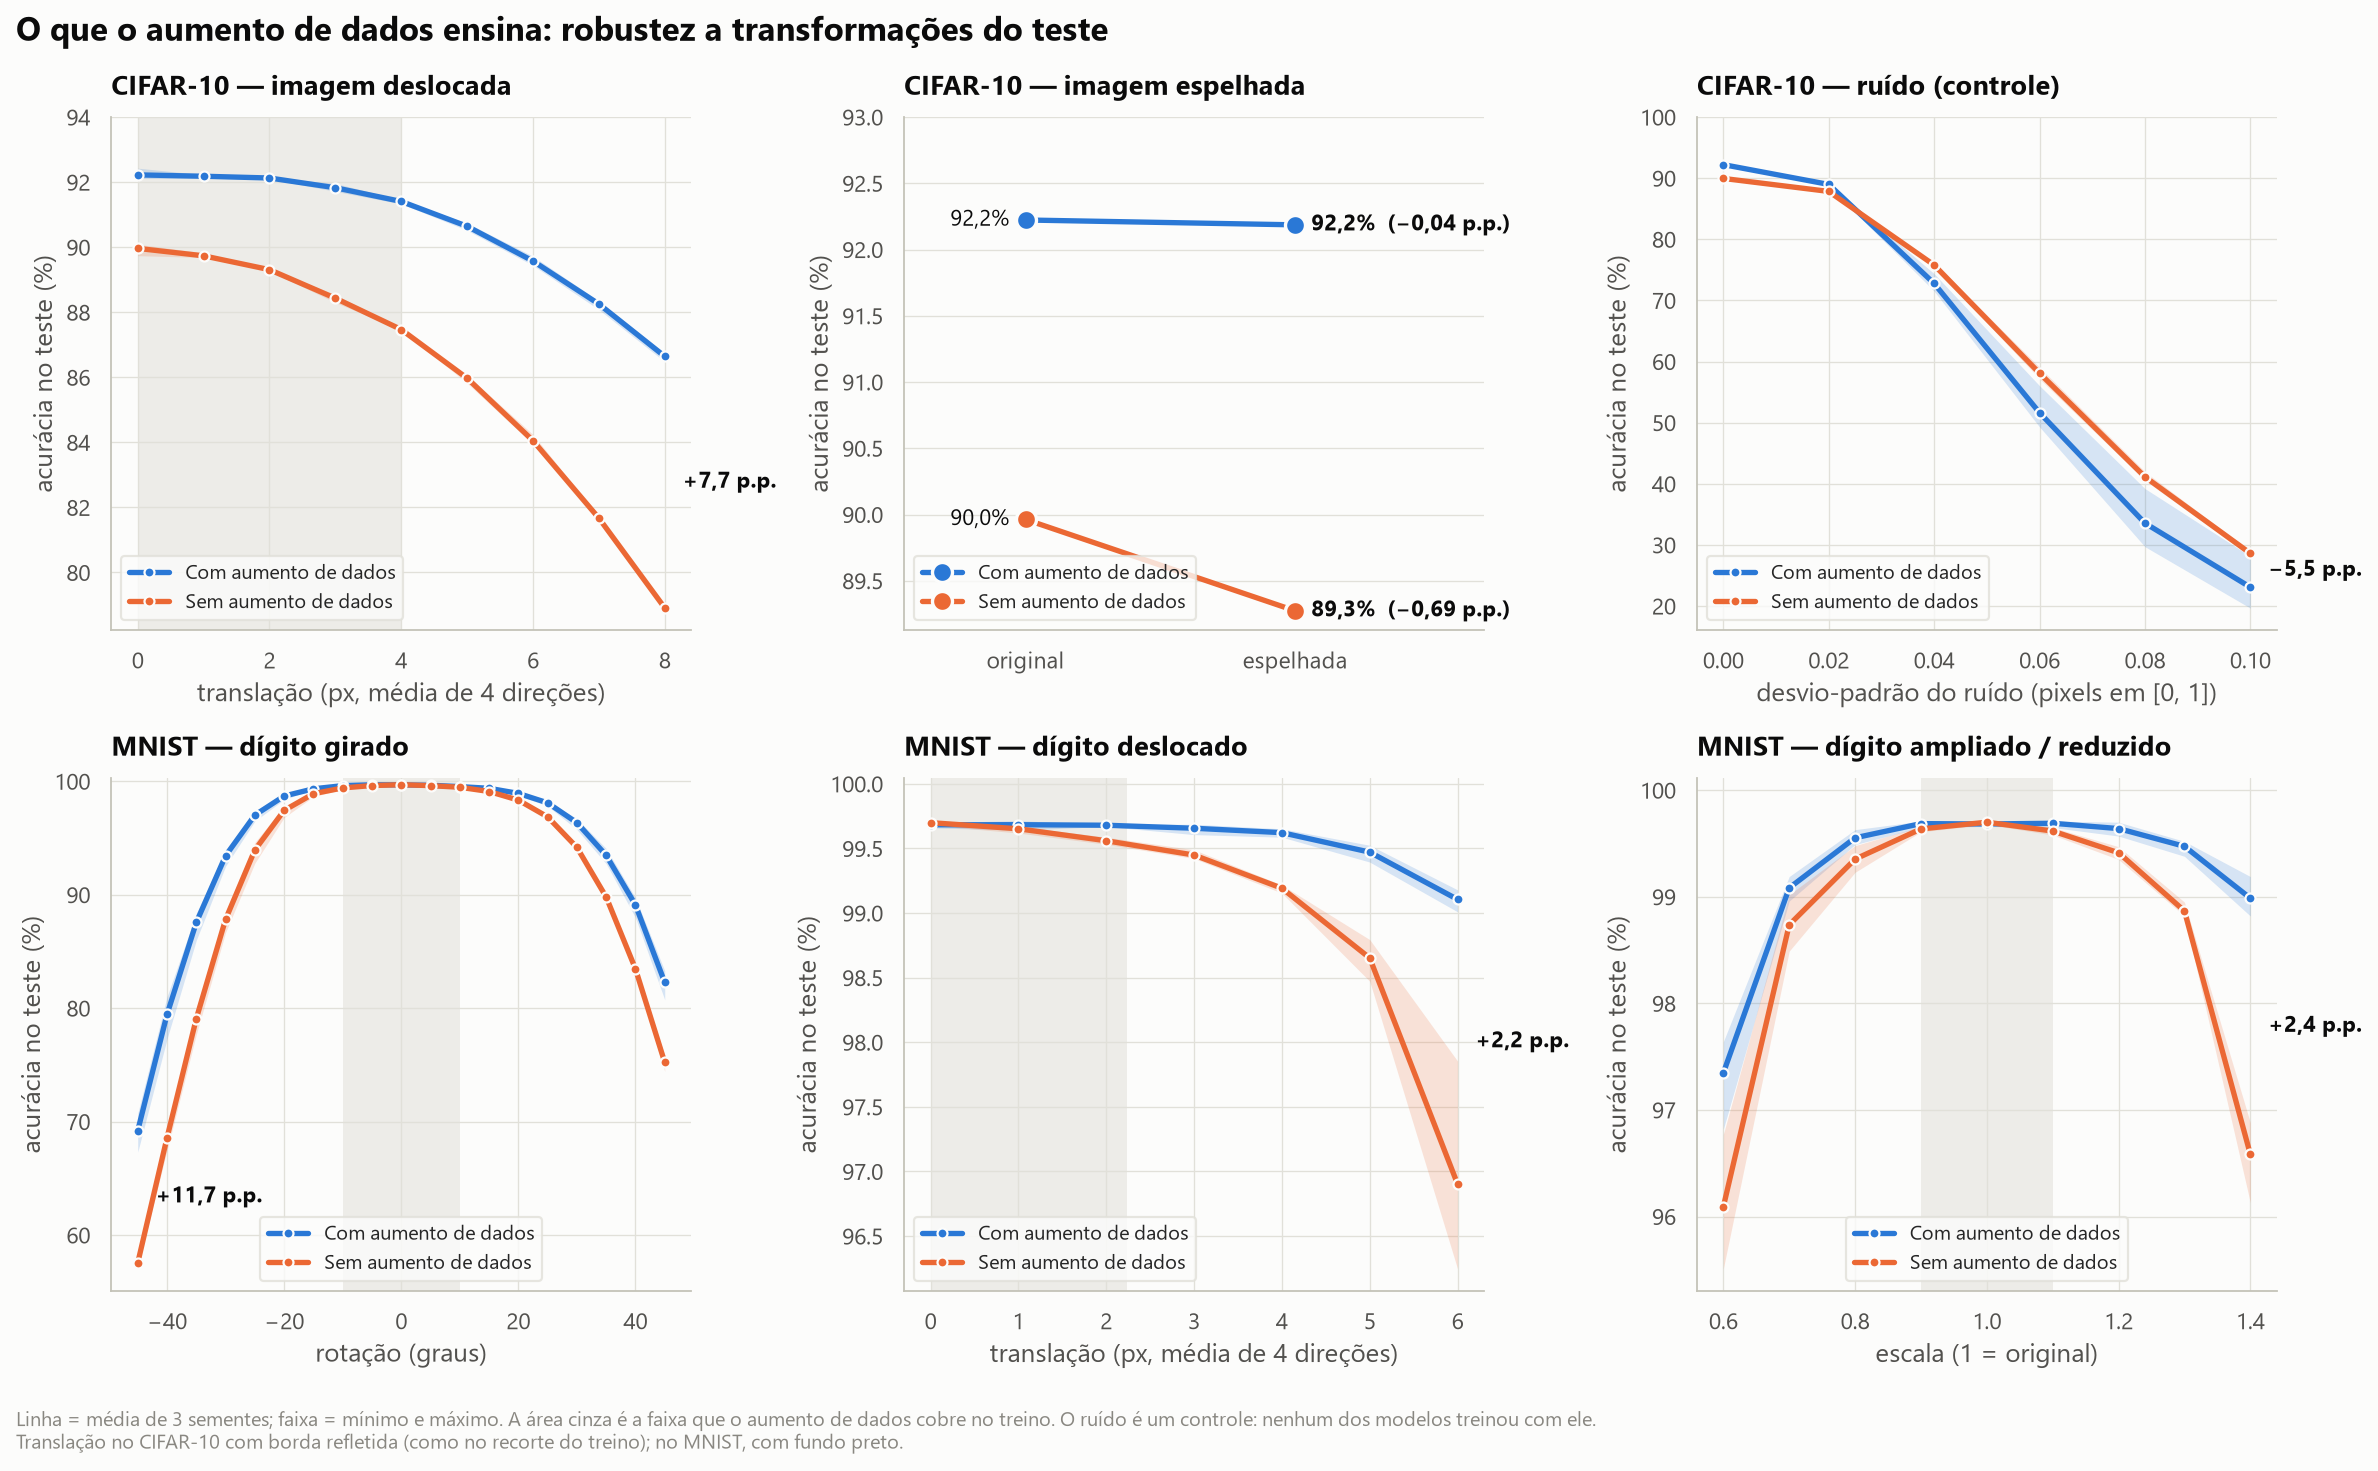

In [11]:
RECALCULAR_ROBUSTEZ = False  # True: reavalia os 12 modelos no teste transformado (~5 min, GPU)
arq = ROOT / "results" / "ablacao" / "robustez.json"
rob = A.robustness(runs) if RECALCULAR_ROBUSTEZ or not arq.exists() else json.loads(arq.read_text(encoding="utf-8"))
A.fig_robust(rob)
mostra("ablacao_robustez.png", 1000)

In [12]:
def media_sementes(ds, cfg, chave, i=None):
    S = rob[ds][cfg]
    v = [S[s][chave] if i is None else S[s][chave]["acc"][i] for s in S]
    return sum(v) / len(v)

def x_de(ds, chave, valor):
    return next(iter(rob[ds]["com"].values()))[chave]["x"].index(valor)

casos = [("cifar10", "original", None, "CIFAR-10 original"),
         ("cifar10", "flip", None, "CIFAR-10 espelhado"),
         ("cifar10", "shift", x_de("cifar10", "shift", 4), "CIFAR-10 deslocado 4 px"),
         ("cifar10", "shift", x_de("cifar10", "shift", 8), "CIFAR-10 deslocado 8 px"),
         ("cifar10", "noise", x_de("cifar10", "noise", 0.06), "CIFAR-10 com ruído σ = 0,06 (controle)"),
         ("mnist", "original", None, "MNIST original"),
         ("mnist", "rot", x_de("mnist", "rot", 45), "MNIST girado 45°"),
         ("mnist", "rot", x_de("mnist", "rot", -45), "MNIST girado −45°"),
         ("mnist", "shift", x_de("mnist", "shift", 6), "MNIST deslocado 6 px"),
         ("mnist", "scale", x_de("mnist", "scale", 1.4), "MNIST ampliado 1,4×"),
         ("mnist", "noise", x_de("mnist", "noise", 0.2), "MNIST com ruído σ = 0,2 (controle)")]
pd.DataFrame([{"teste": nome, "com aumento": media_sementes(ds, "com", k, i),
               "sem aumento": media_sementes(ds, "sem", k, i)} for ds, k, i, nome in casos]
             ).assign(diferença=lambda d: 100 * (d["com aumento"] - d["sem aumento"])
             ).style.format({"com aumento": pct, "sem aumento": pct,
                             "diferença": lambda v: f"{v:+.1f} p.p.".replace(".", ",", 1)}).hide(axis="index")

teste,com aumento,sem aumento,diferença
CIFAR-10 original,"92,22%","89,96%","+2,3 p.p."
CIFAR-10 espelhado,"92,19%","89,27%","+2,9 p.p."
CIFAR-10 deslocado 4 px,"91,41%","87,47%","+3,9 p.p."
CIFAR-10 deslocado 8 px,"86,64%","78,91%","+7,7 p.p."
"CIFAR-10 com ruído σ = 0,06 (controle)","51,63%","58,10%","-6,5 p.p."
MNIST original,"99,68%","99,70%","-0,0 p.p."
MNIST girado 45°,"82,27%","75,22%","+7,1 p.p."
MNIST girado −45°,"69,20%","57,54%","+11,7 p.p."
MNIST deslocado 6 px,"99,11%","96,90%","+2,2 p.p."
"MNIST ampliado 1,4×","98,99%","96,58%","+2,4 p.p."


- **Espelhamento:** o modelo com aumento de dados é indiferente à orientação (92,22% → 92,19%); o modelo sem ele perde 0,7 p.p. quando a imagem é espelhada.
- **Deslocamento:** com 8 px, o modelo sem aumento de dados perde 11,1 p.p. e o modelo com aumento perde 5,6 p.p., a metade. A convolução e o *pooling* dão só uma tolerância parcial a deslocamentos.
- **MNIST:** é aqui que o componente vale no MNIST. Dentro da faixa vista no treino os dois modelos praticamente empatam, porque o teste do MNIST já vem centralizado e normalizado como o treino. Fora dela o modelo com aumento é bem mais robusto: +7 a +12 p.p. com rotação de 45°, +2,2 p.p. com 6 px de deslocamento e +2,4 p.p. com o dígito 40% maior.
- **Ruído (controle):** com ruído gaussiano, transformação que nenhum modelo viu, os modelos **com** aumento de dados foram *menos* robustos nos dois datasets (−6,5 p.p. no CIFAR-10 e −14,0 p.p. no MNIST, sem sobreposição entre sementes). O aumento de dados não dá robustez geral: dá robustez às transformações que ele mostra no treino, e pode até piorar a robustez a outras.

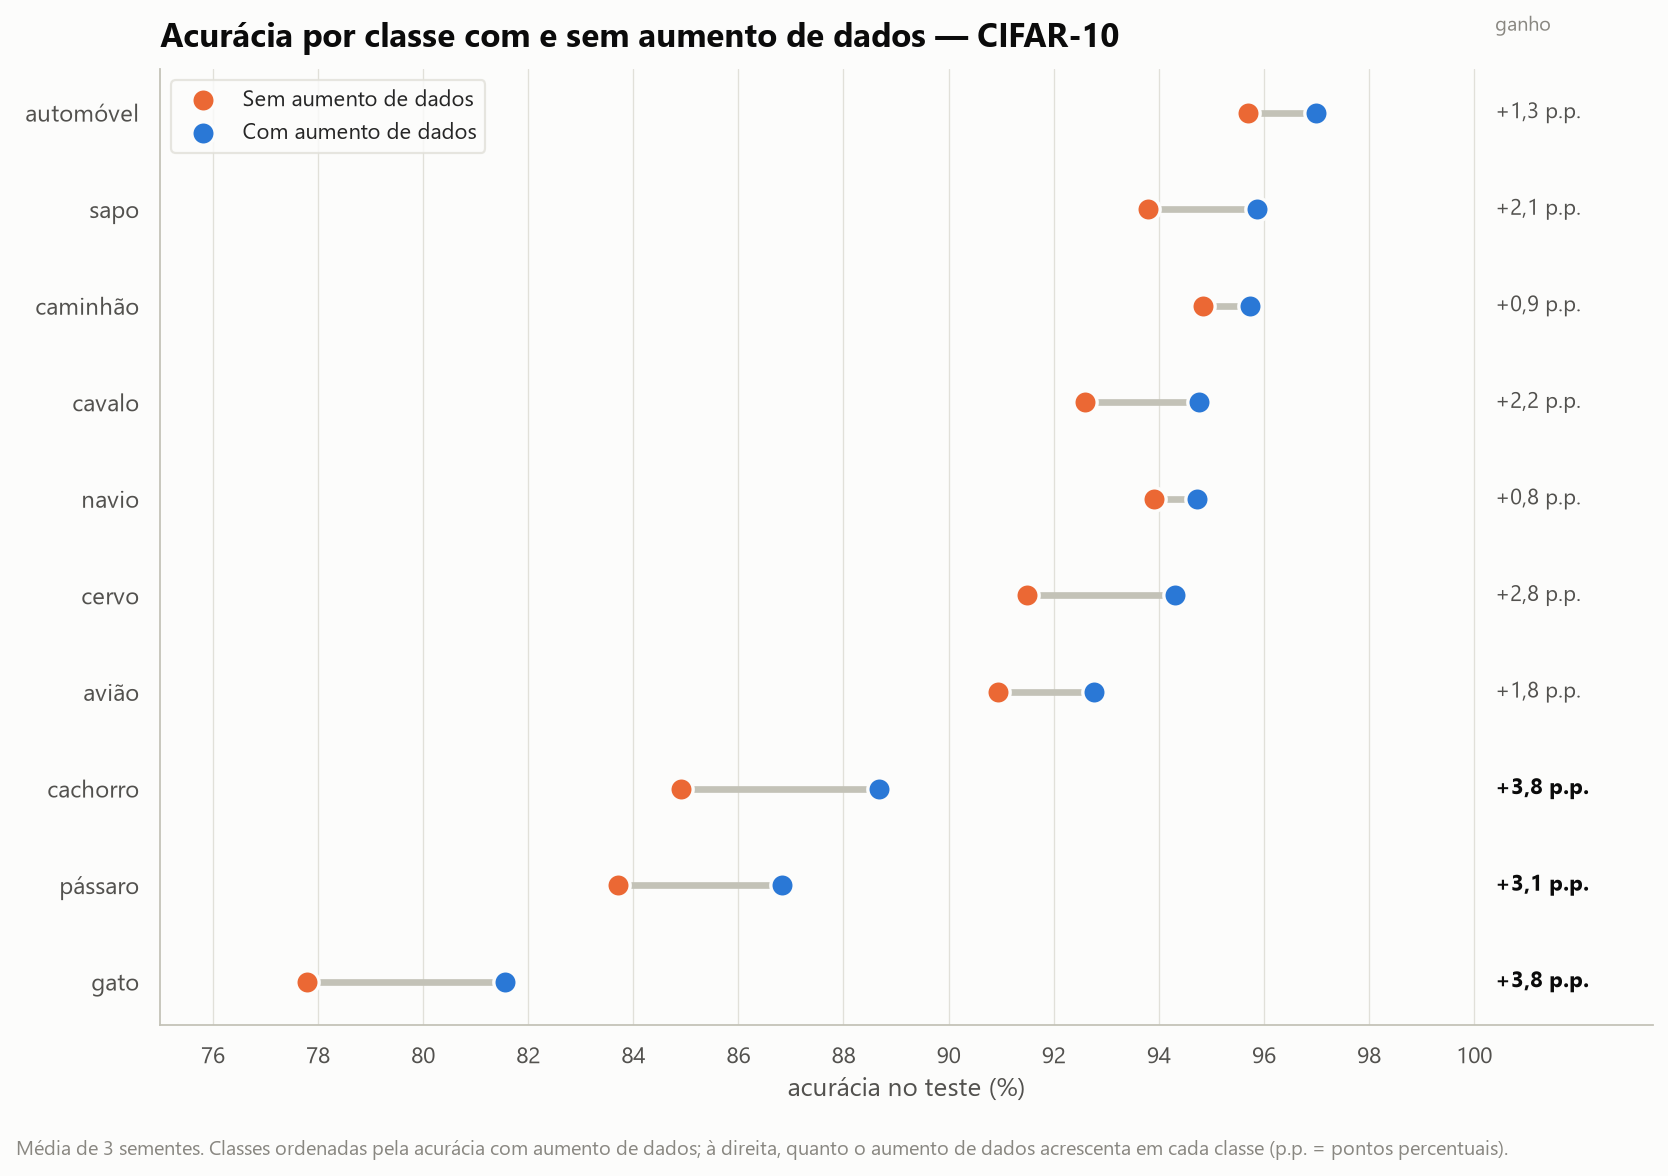

In [13]:
A.fig_per_class(runs)
mostra("ablacao_por_classe_cifar10.png", 800)

O aumento de dados melhora **todas** as classes do CIFAR-10, e mais as classes difíceis: cachorro (84,9% → 88,7%) e gato (77,8% → 81,6%) ganham 3,8 p.p. cada, pássaro 3,1. Nos veículos o ganho fica entre 0,8 e 1,8 p.p. Animais aparecem em mais poses e enquadramentos, justamente as variações que o recorte e o espelhamento multiplicam. São as mesmas classes em que a ResNet18 pré-treinada levava mais vantagem na APS anterior.

## 4. Qual nossa opinião sobre o impacto do componente?

**No CIFAR-10, o aumento de dados é essencial.** Ele vale 2,3 p.p. de acurácia (22% menos erros), reduz o sobreajuste pela metade e melhora todas as classes, com resultados consistentes nas três sementes. E quase não custa nada: não acrescenta parâmetros, não muda a inferência e deixa a época de treino cerca de 5% mais lenta, porque as transformações rodam na GPU.

**Mas não é "o" componente da regularização.** Ele explica 38% da queda que a APS anterior via ao desligar toda a regularização; o resto vem de dropout, weight decay e label smoothing. A MinhaCNN depende do conjunto.

**No MNIST, ele não melhora o teste — e nós o manteríamos.** O teste do MNIST tem as mesmas condições do treino, então o placar não muda; mas o modelo com aumento de dados é muito mais robusto a dígitos girados, deslocados ou de outro tamanho, que é o que aparece fora do conjunto de dados. Julgando só pela acurácia de teste, concluiríamos errado que o componente é inútil.

**O aumento de dados funciona porque é conhecimento sobre o problema.** Cada transformação diz o que *não* muda a classe — espelhar um gato não muda nada, espelhar um "2" muda tudo. O ganho aparece exatamente nas transformações treinadas, transformações fortes demais atrapalham (±8 px) e não há proteção contra o que não foi treinado (ruído). Por isso o componente fica na MinhaCNN, escolhido para cada problema.

**Próximos passos:** treinar por mais épocas (a melhor época foi a última); testar aumentos de outro tipo (*Cutout*, RandAugment, *mixup*) em vez de recortes maiores; incluir ruído no aumento se a robustez a ruído importar; e usar o espelhamento também no teste (*test-time augmentation*).

O texto completo, com metodologia, limitações e referências, está em `relatorio/Relatorio_Ablacao_CNN.pdf`.